# Modeling

**Goal:** train and compare models that predict the energy use of non-residential buildings in Seattle, starting from the features built in `02_feature_engineering.ipynb`.

## 0. Setup

Imports and load the dataset with the engineered features.

`buildings_feature_engineered.parquet` is the output of `02_feature_engineering.ipynb`.

To generate it, run `notebooks/01_eda.ipynb` then `notebooks/02_feature_engineering.ipynb` from top to bottom. The file is written to `data/processed/buildings_feature_engineered.parquet`.

In [1]:
from collections.abc import Callable
from functools import partial
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostRegressor
from IPython.display import display
from pandas.io.formats.style import Styler
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

df = pd.read_parquet("../data/processed/buildings_feature_engineered.parquet")
print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns")

Dataset: 1535 rows x 12 columns


## 1. Train/test split

The test set is set aside now and is only used once, for the final evaluation. Everything else (imputation, encoding, feature selection, hyperparameters) is fitted on the training set only, inside the cross-validation.

- **Split:** 80% train / 20% test, fixed `random_state` for reproducibility.
- **Target:** `SiteEnergyUse(kBtu)` is right-skewed, so it is modeled as `log10` (decision of notebook 1). `y` is kept in kBtu: the model will be wrapped in a `TransformedTargetRegressor` (`func=np.log10`), which fits on `log10(y)` and returns predictions in kBtu, so the metrics are computed in kBtu.
- **Stratification:** a continuous target cannot be stratified directly. The target is cut into 10 quantile bins (deciles; the bins are identical on `y` and on `log10(y)`, since the log is monotonic), and the split is stratified on these bins so that the training and test sets cover the whole range of consumption, including the few very large buildings. The bins are computed on the whole dataset, but they are only used to draw the split: they are not a feature and never reach the models.

The check below compares the `log10` target distributions of the two sets (the log is only computed for display).

In [2]:
TARGET = "SiteEnergyUse(kBtu)"
RANDOM_STATE = 42

X = df.drop(columns=TARGET)
y = df[TARGET]  # kBtu; the log10 transform is done by TransformedTargetRegressor

# Stratify on deciles of the target (the bins are the same on y and log10(y))
y_bins = pd.qcut(y, q=10, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y_bins, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

Train: 1228 rows | Test: 307 rows


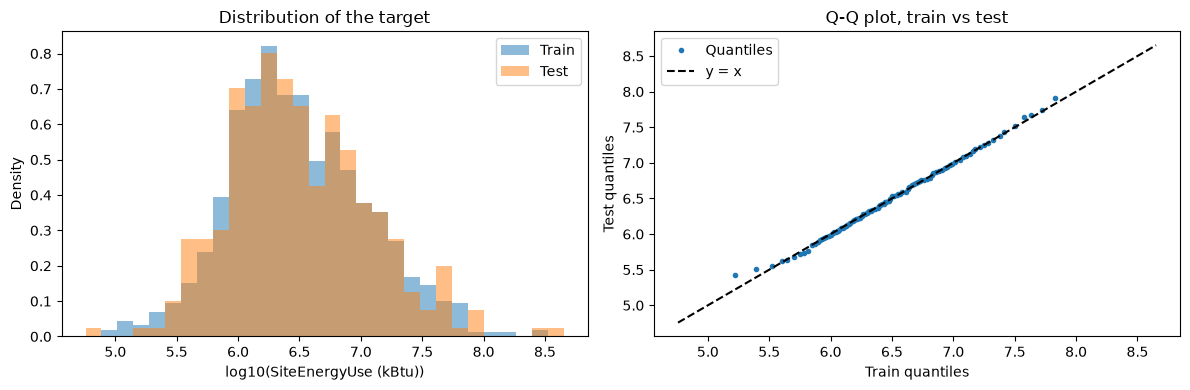

,Train,Test
count,1228.000,307.000
mean,6.492,6.498
std,0.564,0.577
min,4.902,4.757
25%,6.101,6.087
50%,6.437,6.429
75%,6.861,6.872
max,8.467,8.652


In [3]:
# Check: log10(y) distributions of the two sets (for display only)
log_train, log_test = np.log10(y_train), np.log10(y_test)
log_all = np.log10(y)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.linspace(log_all.min(), log_all.max(), 31)
axes[0].hist(log_train, bins=bins, density=True, alpha=0.5, label="Train")
axes[0].hist(log_test, bins=bins, density=True, alpha=0.5, label="Test")
axes[0].set_xlabel("log10(SiteEnergyUse (kBtu))")
axes[0].set_ylabel("Density")
axes[0].set_title("Distribution of the target")
axes[0].legend()

quantiles = np.linspace(0.01, 0.99, 99)
axes[1].plot(
    log_train.quantile(quantiles), log_test.quantile(quantiles), ".", label="Quantiles"
)
axes[1].plot(
    [log_all.min(), log_all.max()], [log_all.min(), log_all.max()], "k--", label="y = x"
)
axes[1].set_xlabel("Train quantiles")
axes[1].set_ylabel("Test quantiles")
axes[1].set_title("Q-Q plot, train vs test")
axes[1].legend()

plt.tight_layout()
plt.show()

summary = pd.DataFrame({"Train": log_train.describe(), "Test": log_test.describe()})
display(summary.round(3))

In [4]:
counts = (
    pd.DataFrame(
        {
            "Train": X_train["PrimaryPropertyType"].value_counts(),
            "Test": X_test["PrimaryPropertyType"].value_counts(),
        }
    )
    .fillna(0)
    .astype(int)
)
counts["Test share"] = (counts["Test"] / (counts["Train"] + counts["Test"])).round(3)
counts.sort_values("Train", ascending=False)

,Train,Test,Test share
PrimaryPropertyType,,,
Small- and Mid-Sized Office,226,60,0.210
Other,197,48,0.196
Warehouse,147,38,0.205
Large Office,131,38,0.225
Mixed Use Property,80,24,0.231
Retail Store,73,12,0.141
Hotel,57,18,0.240
Worship Facility,56,13,0.188
Distribution Center,49,4,0.075


### Checks

- The stratification works. The two sets have almost the same mean (6.49 vs 6.50 in log10), median (6.44 vs 6.43) and spread, and the points of the Q-Q plot follow the diagonal over the whole range, including the largest consumers.
- The target is strictly positive (minimum of 4.76 in log10), so the log10 transform is always defined. The largest building of the test set (8.65) is above the maximum of the training set (8.47): the models will have to predict beyond the values they were trained on.
- Most property types have about 20% of their buildings in the test set. By chance, no hospital ends up in the test set. The split is kept as is: changing the random seed to fix this would mean choosing the test set after looking at it. The behavior of the models on hospitals is assessed through cross-validation instead, where each building is used once for validation.

## 2. Checks on the training set

Everything in this section uses `X_train` and `y_train` only. The exploration of notebooks 1 and 2 is not repeated: this section keeps the checks that drive the preprocessing choices (correlations with the target, property type, redundancy among the size variables). The signals of the engineered features (`ParkingShare`, `FloorAreaPerFloor`) hold on the training set, as in notebook 2.

As in notebook 2, the **intensity** (energy use divided by the building area) is used next to the target itself, because the building area dominates the total energy use and hides the other signals.

### Correlations with the target

Spearman rank correlations (insensitive to the skew, no need to log-transform).

In [5]:
train = X_train.assign(
    log_y=np.log10(y_train),
    log_intensity=np.log10(y_train / X_train["PropertyGFABuilding(s)"]),
)

numeric = [
    "PropertyGFABuilding(s)",
    "NumberofFloors",
    "NumberofBuildings",
    "FloorAreaPerFloor",
    "ParkingShare",
    "HasMixedUsage",
    "Latitude",
    "Longitude",
]
corr = pd.DataFrame(
    {
        "vs log10(y)": train[numeric].corrwith(train["log_y"], method="spearman"),
        "vs log10(intensity)": train[numeric].corrwith(
            train["log_intensity"], method="spearman"
        ),
    }
)
corr.round(2)

,vs log10(y),vs log10(intensity)
PropertyGFABuilding(s),0.71,0.11
NumberofFloors,0.47,0.16
NumberofBuildings,0.12,0.09
FloorAreaPerFloor,0.23,-0.08
ParkingShare,0.31,0.21
HasMixedUsage,0.10,0.04
Latitude,0.06,0.12
Longitude,-0.04,-0.02


The total energy use is mostly driven by the building area (Spearman 0.71 with `log10(y)`), which hides everything else. Against the intensity (energy use per unit of area), the picture changes:

- `ParkingShare` is the strongest of the engineered features (0.21 with the intensity, 0.31 with `log10(y)`, because parking is correlated with large buildings).
- `FloorAreaPerFloor` is weak and changes sign: +0.23 with `log10(y)` (wider buildings are larger) but -0.08 with the intensity.
- `HasMixedUsage` (0.04), `NumberofBuildings` (0.09) and `Longitude` (-0.02) are weak. `NumberofFloors` (0.16) and `Latitude` (0.12) are modest.
- A rank correlation only sees monotonic relationships. The construction period and the property type are categorical and not in this table; their relationships were studied in notebooks 1 and 2.

These are descriptive values on the training set. The real test of a feature is its contribution to the model, assessed later with cross-validation.

The property type is categorical, so it is not in this table: its relationship with the intensity is shown below.

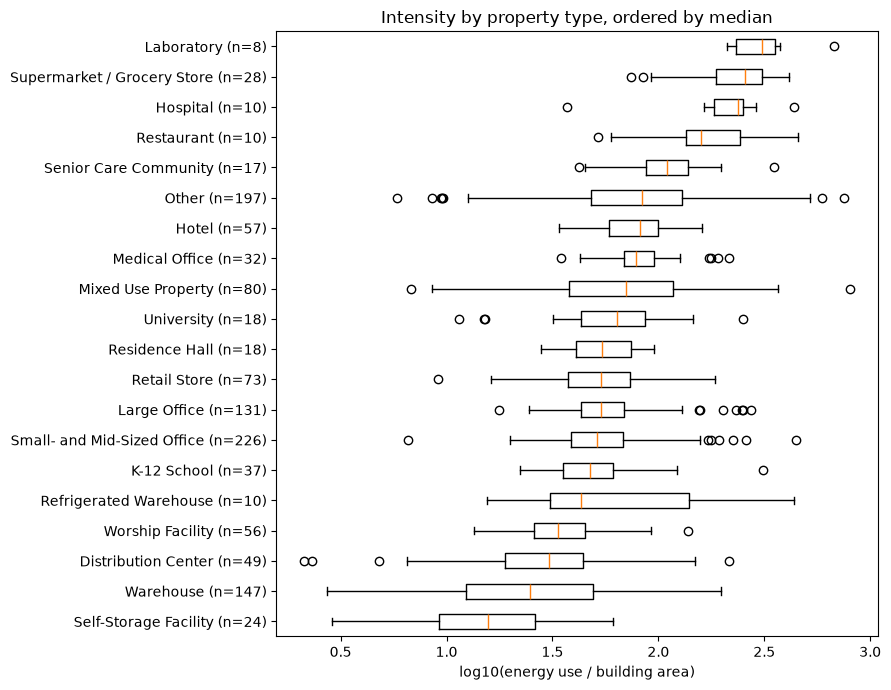

In [6]:
order = (
    train.groupby("PrimaryPropertyType")["log_intensity"].median().sort_values().index
)
groups = [train.loc[train["PrimaryPropertyType"] == t, "log_intensity"] for t in order]

fig, ax = plt.subplots(figsize=(9, 7))
ax.boxplot(
    groups,
    tick_labels=[f"{t} (n={len(g)})" for t, g in zip(order, groups)],
    orientation="horizontal",
)
ax.set_xlabel("log10(energy use / building area)")
ax.set_title("Intensity by property type, ordered by median")
plt.tight_layout()
plt.show()

The property type is the strongest driver of the energy use per unit of area. The median intensity ranges from about 1.2 (Self-Storage Facility) to about 2.5 (Laboratory) in log10: a laboratory uses about 20 times more energy per square foot than a self-storage facility. The order matches the business intuition: laboratories, supermarkets (refrigeration), hospitals (24/7 operation) and restaurants (cooking) are at the top, storage buildings at the bottom.

The spread inside each type varies a lot:
- Offices, the most frequent types (226 and 131 buildings), have narrow boxes: their intensity is homogeneous, so they should be well predicted.
- The catch-all categories (Other, Mixed Use Property) and Warehouse have wide boxes: they group buildings with very different actual uses. Other is the second most frequent type (197 buildings), so most prediction errors are expected there.
- The rarest types (8 to 10 buildings) are among the most extreme. Grouping rare categories at encoding time (`min_frequency`, `max_categories`) would merge laboratories, hospitals and refrigerated warehouses into a single column and lose the strongest signal of the dataset: all property types are therefore kept as separate categories.

### Redundancy among the size variables

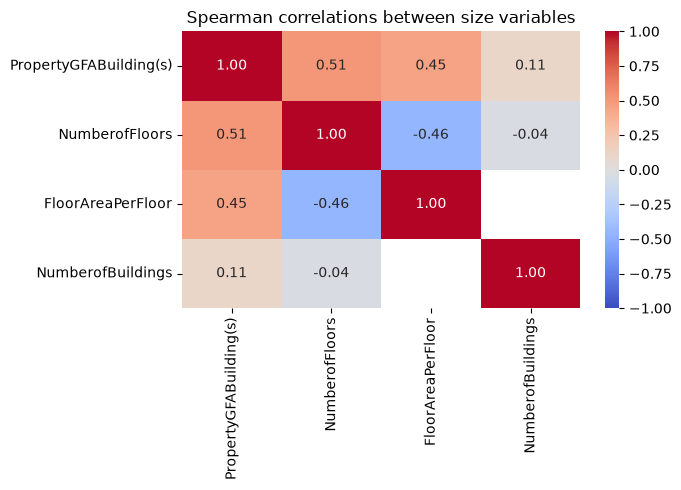

In [7]:
size_cols = [
    "PropertyGFABuilding(s)",
    "NumberofFloors",
    "FloorAreaPerFloor",
    "NumberofBuildings",
]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    train[size_cols].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    ax=ax,
)
ax.set_title("Spearman correlations between size variables")
plt.tight_layout()
plt.show()

- The size variables are moderately correlated (0.45 to 0.51), and `NumberofBuildings` is almost independent of them.
- By construction, area = floors × area per floor: any one of the three can be computed exactly from the other two. The linear model therefore gets only two of them. Tree-based models can keep all three, but their importance will have to be read together.
- `FloorAreaPerFloor` is missing for all campuses (hence the empty cell in the heatmap), so its missing values carry information: an indicator column will be added at imputation.

## 3. Preprocessing

Two preprocessors, one per family of models. Both are `ColumnTransformer`s that will be the first step of a pipeline, so that imputation, scaling and encoding are fitted on the training folds only.

| | Linear models | Tree-based models |
|---|---|---|
| Skewed sizes (`PropertyGFABuilding(s)`, `NumberofFloors`, `NumberofBuildings`) | `log10` | as is (trees only use the order of the values) |
| Size variables | area + floors; `FloorAreaPerFloor` is dropped (area = floors × area per floor, a linear model cannot take all three) | all three |
| Missing values (`FloorAreaPerFloor`, `NumberofFloors`) | median + missing indicator | median + missing indicator |
| Scaling | `StandardScaler` on the numeric variables (needed for regularisation); binary variables and missing indicators are never scaled, to stay readable | none |
| Categories (`PrimaryPropertyType`, `Neighborhood`, `ConstructionPeriod`) | one-hot, unknown category ignored | one-hot, unknown category ignored |
| `ParkingShare`, `Latitude`, `Longitude` | scaled | as is |
| `HasMixedUsage` (binary) | as is | as is |

- The missing `FloorAreaPerFloor` values are mostly campuses (see section 2). The tree models keep the missing indicator for them. The linear model does not use this feature, so `NumberofBuildings` is its only campus signal. An indicator only exists for columns with missing values in the training data.
- No `min_frequency` in the one-hot encoding: the rare property types are the most extreme ones and must keep their own column.
- Which of the three size variables to drop for the linear model is a modeling choice: `FloorAreaPerFloor` is dropped because it has fewer imputed values (11 instead of 51), and floor area has no physical meaning for a campus.

In [8]:
X_train.isna().sum()

PropertyGFABuilding(s)     0
PrimaryPropertyType        0
NumberofFloors            11
NumberofBuildings          0
Neighborhood               0
Latitude                   0
Longitude                  0
ParkingShare               0
HasMixedUsage              0
ConstructionPeriod         0
FloorAreaPerFloor         51
dtype: int64

In [9]:
CATEGORICAL = ["PrimaryPropertyType", "Neighborhood", "ConstructionPeriod"]
LOG_COLS = ["PropertyGFABuilding(s)", "NumberofFloors", "NumberofBuildings"]
PLAIN_NUMERIC_COLS = [
    "ParkingShare",
    "Latitude",
    "Longitude",
]  # no log; scaled for the linear models only
BINARY_COLS = ["HasMixedUsage"]  # already 0/1, never scaled
TREE_ONLY_COLS = [
    "FloorAreaPerFloor"
]  # redundant with the two size variables for a linear model


def make_one_hot():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)


def make_imputer(add_indicator):
    return SimpleImputer(strategy="median", add_indicator=add_indicator)


def make_linear_preprocessor():
    """Log of the skewed sizes, scaling, imputation, one-hot encoding.

    The missing indicator is generated by its own step, outside of the sub-pipeline,
    so that it is not scaled.
    """
    log_pipeline = make_pipeline(
        FunctionTransformer(np.log10, feature_names_out="one-to-one"),
        StandardScaler(),
        make_imputer(add_indicator=False),
    )
    return ColumnTransformer(
        [
            ("log", log_pipeline, LOG_COLS),
            ("missing", MissingIndicator(features="missing-only"), ["NumberofFloors"]),
            ("plain_numeric", StandardScaler(), PLAIN_NUMERIC_COLS),
            ("binary", "passthrough", BINARY_COLS),
            ("cat", make_one_hot(), CATEGORICAL),
        ],
        remainder="drop",  # FloorAreaPerFloor
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def make_tree_preprocessor():
    """No transformation of the values: imputation (with indicator) and one-hot encoding."""
    return ColumnTransformer(
        [
            ("num", make_imputer(add_indicator=True), LOG_COLS + TREE_ONLY_COLS),
            ("plain", "passthrough", PLAIN_NUMERIC_COLS + BINARY_COLS),
            ("cat", make_one_hot(), CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

### Check

Each preprocessor is fitted on the training set and applied to both sets (only to check the output: during the modeling, the fit happens inside the cross-validation). The output must have no missing value, and the linear one must have centered numeric columns.

In [10]:
for name, make in [
    ("Linear", make_linear_preprocessor),
    ("Trees", make_tree_preprocessor),
]:
    prep = make().fit(X_train)
    out_train, out_test = prep.transform(X_train), prep.transform(X_test)
    assert not out_train.isna().any().any() and not out_test.isna().any().any()
    print(f"{name}: {X_train.shape[1]} -> {out_train.shape[1]} columns")
    indicators = [c for c in out_train.columns if c.startswith("missingindicator")]
    print(f"  missing indicators: {indicators}")

linear_out = make_linear_preprocessor().fit_transform(X_train)
linear_out.iloc[:, :6].astype(float).describe().loc[
    ["mean", "std", "min", "max"]
].round(2)

Linear: 11 -> 46 columns
  missing indicators: ['missingindicator_NumberofFloors']
Trees: 11 -> 48 columns
  missing indicators: ['missingindicator_NumberofFloors', 'missingindicator_FloorAreaPerFloor']


,PropertyGFABuilding(s),NumberofFloors,NumberofBuildings,missingindicator_NumberofFloors,ParkingShare,Latitude
mean,0.00,-0.00,-0.00,0.01,0.00,0.00
std,1.00,1.00,1.00,0.09,1.00,1.00
min,-1.82,-1.14,-0.17,0.00,-0.45,-2.26
max,3.77,3.90,11.81,1.00,5.10,2.48


## 4. Evaluation protocol

| Element | Choice |
|---|---|
| Cross-validation | 5 folds, stratified on the deciles of `y_train`, built once and shared by all the models |
| Decision metric | MAE on `log10` (`log10_mae`): the typical error as a factor (10^0.1 ≈ 1.26, i.e. about 26%), with the same weight for small and large buildings |
| Reported metrics | R², MAE and RMSE in kBtu, dominated by the largest buildings |
| Baseline | `DummyRegressor`: the reference any model must beat |
| Overfitting signal | Gap between the mean train and validation scores (positive when the model does worse on validation) |

All the models learn `log10(y)` through a `TransformedTargetRegressor` and predict in kBtu.

`evaluate_model` cross-validates a model and returns one row of the results table. Scorer keys starting with `neg_` are errors: scikit-learn negates them, so the sign is flipped back and the prefix removed. Two display functions show the results: the decision table (log10 MAE only) and the metrics in kBtu.

In [11]:
def evaluate_model(
    model: Any,
    X: pd.DataFrame,
    y: pd.Series,
    cv: list[tuple[np.ndarray, np.ndarray]],
    scorers: dict[str, str | Callable],
    model_name: str,
) -> dict[str, Any]:
    """Cross-validate a model on explicit folds and return one row of the summary table.

    Train and validation scores are averaged over the folds (mean and std). Keys starting
    with 'neg_' are errors: the sign is flipped back and the prefix removed. The gap is
    positive when the model does worse on validation (val - train for errors, train - val otherwise).
    """
    results = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scorers,
        return_train_score=True,
    )

    row: dict[str, Any] = {
        "model": model_name,
        "fit_time_mean": results["fit_time"].mean(),
    }
    for key in scorers:
        is_error = key.startswith("neg_")
        name = key.removeprefix("neg_")
        sign = -1 if is_error else 1  # scikit-learn negates errors: flip them back

        train = sign * results[f"train_{key}"]
        val = sign * results[f"test_{key}"]

        row[f"{name}_train_mean"] = train.mean()
        row[f"{name}_train_std"] = train.std()
        row[f"{name}_val_mean"] = val.mean()
        row[f"{name}_val_std"] = val.std()
        row[f"{name}_gap"] = (
            val.mean() - train.mean() if is_error else train.mean() - val.mean()
        )
    return row


def with_log_target(regressor: Any) -> TransformedTargetRegressor:
    """Wrap a regressor so that it learns log10(y) and predicts in kBtu."""
    return TransformedTargetRegressor(
        regressor=regressor, func=np.log10, inverse_func=partial(np.power, 10.0)
    )


def decision_table(results: pd.DataFrame) -> Styler:
    """Log10 MAE only, one row per model; the best validation score is in bold."""
    table = pd.DataFrame(
        {
            "train": results["log10_mae_train_mean"],
            "validation": results["log10_mae_val_mean"],
            "validation std": results["log10_mae_val_std"],
            "gap": results["log10_mae_gap"],
            "error factor": 10 ** results["log10_mae_val_mean"],
            "fit time (s)": results["fit_time_mean"],
        }
    )
    return (
        table.style.format("{:.3f}")
        .format("{:.2f}", subset=["error factor", "fit time (s)"])
        .highlight_min(subset=["validation"], props="font-weight: bold")
    )


def kbtu_table(results: pd.DataFrame) -> Styler:
    """Validation R2, MAE and RMSE in kBtu, one row per model."""
    table = pd.DataFrame(
        {
            "R2": results["r2_val_mean"],
            "MAE (kBtu)": results["mean_absolute_error_val_mean"],
            "RMSE (kBtu)": results["root_mean_squared_error_val_mean"],
        }
    )
    return table.style.format(
        {"R2": "{:.3f}", "MAE (kBtu)": "{:,.0f}", "RMSE (kBtu)": "{:,.0f}"}
    )

### Folds and scorers

The folds are recomputed on the deciles of `y_train` (not the `y_bins` of the train/test split). The list of positional indices is passed as is to `evaluate_model`.

In [12]:
y_train_bins = pd.qcut(y_train, q=10, labels=False)

cv = list(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(
        X_train, y_train_bins
    )
)

for i, (train_idx, val_idx) in enumerate(cv, start=1):
    print(f"Fold {i}: train {len(train_idx)} rows | validation {len(val_idx)} rows")
assert sorted(np.concatenate([val for _, val in cv])) == list(range(len(X_train)))

Fold 1: train 982 rows | validation 246 rows
Fold 2: train 982 rows | validation 246 rows
Fold 3: train 982 rows | validation 246 rows
Fold 4: train 983 rows | validation 245 rows
Fold 5: train 983 rows | validation 245 rows


In [13]:
def log10_mae(y_true, y_pred):
    return mean_absolute_error(np.log10(y_true), np.log10(y_pred))


scorers = {
    "r2": "r2",
    "neg_mean_absolute_error": "neg_mean_absolute_error",
    "neg_root_mean_squared_error": "neg_root_mean_squared_error",
    "neg_log10_mae": make_scorer(log10_mae, greater_is_better=False),
}

### Baseline: dummy model

A `DummyRegressor` predicts the mean of `log10(y)` for every building (the geometric mean in kBtu). It is wrapped with `with_log_target` like the other models, so it is evaluated under the same conditions: **it is the reference any model must beat**.

Expected: no gap between train and validation, since the model learns nothing from the features. The R² is slightly negative, even on the training set. R² compares a model with a constant prediction equal to the average consumption (about 8.0 million kBtu). The dummy predicts a typical building instead (the mean of log10(y), about 3.1 million kBtu), which is lower because the average is pulled up by a few very large buildings. It is therefore slightly worse than the R² reference, by construction.

In [14]:
dummy = with_log_target(DummyRegressor(strategy="mean"))
baseline = evaluate_model(dummy, X_train, y_train, cv, scorers, "Dummy (mean of log10)")

baseline_results = pd.DataFrame([baseline]).set_index("model")
display(decision_table(baseline_results))
display(kbtu_table(baseline_results))

,train,validation,validation std,gap,error factor,fit time (s)
model,,,,,,
Dummy (mean of log10),0.451,0.451,0.004,-0.000,2.83,0.01


,R2,MAE (kBtu),RMSE (kBtu)
model,,,
Dummy (mean of log10),-0.073,"6,657,011","19,144,851"


## 5. Model comparison

Three models from three families, with their default settings, on the same folds:

- **Ridge** (linear model with L2 regularisation, `alpha=1`) on the linear preprocessor;
- **Random forest** (bagging of deep trees: 100 trees, no depth limit) on the tree preprocessor;
- **CatBoost** (boosting of symmetric trees: 1000 iterations of depth 6) on the tree preprocessor. `verbose=0` and `allow_writing_files=False` only silence the training log and the `catboost_info/` folder.

The hyperparameters are tuned in section 6.

In [15]:
models = {
    "Ridge (alpha=1)": with_log_target(
        make_pipeline(make_linear_preprocessor(), Ridge())
    ),
    "Random forest (default)": with_log_target(
        make_pipeline(
            make_tree_preprocessor(), RandomForestRegressor(random_state=RANDOM_STATE)
        )
    ),
    "CatBoost (default)": with_log_target(
        make_pipeline(
            make_tree_preprocessor(),
            CatBoostRegressor(
                random_state=RANDOM_STATE, verbose=0, allow_writing_files=False
            ),
        )
    ),
}

rows = [baseline] + [
    evaluate_model(model, X_train, y_train, cv, scorers, name)
    for name, model in models.items()
]
results = pd.DataFrame(rows).set_index("model")
decision_table(results)

,train,validation,validation std,gap,error factor,fit time (s)
model,,,,,,
Dummy (mean of log10),0.451,0.451,0.004,-0.000,2.83,0.01
Ridge (alpha=1),0.209,0.218,0.008,0.009,1.65,0.04
Random forest (default),0.087,0.235,0.004,0.148,1.72,0.73
CatBoost (default),0.104,0.225,0.007,0.121,1.68,0.82


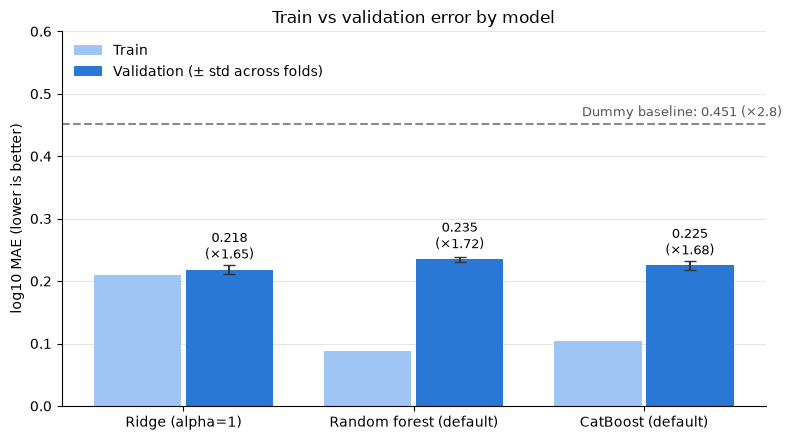

In [16]:
# Same data as the decision table: train vs validation log10 MAE, dummy as a reference line
compared = results.drop(index=baseline["model"])
x = np.arange(len(compared))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(
    x - width / 2 - 0.01,
    compared["log10_mae_train_mean"],
    width,
    color="#9ec5f4",
    label="Train",
)
ax.bar(
    x + width / 2 + 0.01,
    compared["log10_mae_val_mean"],
    width,
    yerr=compared["log10_mae_val_std"],
    capsize=4,
    color="#2a78d6",
    ecolor="#333333",
    label="Validation (± std across folds)",
)
for xi, value in zip(x, compared["log10_mae_val_mean"]):
    ax.annotate(
        f"{value:.3f}\n(×{10**value:.2f})",
        (xi + width / 2 + 0.01, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

dummy_val = baseline["log10_mae_val_mean"]
ax.axhline(dummy_val, color="#8a8a8a", linestyle="--", linewidth=1.5)
ax.text(
    x[-1] + 0.6,
    dummy_val + 0.008,
    f"Dummy baseline: {dummy_val:.3f} (×{10**dummy_val:.1f})",
    ha="right",
    va="bottom",
    color="#555555",
    fontsize=9,
)

ax.set_xticks(x, compared.index)
ax.set_ylim(0, 0.6)
ax.set_ylabel("log10 MAE (lower is better)")
ax.set_title("Train vs validation error by model")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

In [17]:
kbtu_table(results)

,R2,MAE (kBtu),RMSE (kBtu)
model,,,
Dummy (mean of log10),-0.073,"6,657,011","19,144,851"
Ridge (alpha=1),0.723,"3,304,013","9,233,231"
Random forest (default),0.725,"3,416,659","9,346,998"
CatBoost (default),0.722,"3,407,456","9,340,024"


### Reading the comparison

- **All three models beat the baseline by far.** The typical error goes from a factor 2.8 (dummy) to about 1.65: the prediction is usually within a factor 1.65 of the actual energy use.
- **The three families reach the same level**, around 0.22 in log10 MAE, with Ridge slightly ahead. Three very different models stopping at the same level means that the remaining error mostly comes from what the features do not contain (occupancy, equipment, operating hours), not from the choice of model.
- **Why the linear model holds its own.** The main relationship, energy use against building area, is a straight line in log-log. Ridge captures it with a single coefficient. A tree approximates it with steps, and cannot predict beyond the range of its leaves for the largest and smallest buildings.
- **The tree-based models overfit with their default settings**: a gap of 0.12 to 0.15, against 0.009 for Ridge. This is what the hyperparameter search of section 6 addresses.
- In kBtu, the models are also close (validation R² of about 0.72 for all three). These metrics are dominated by the largest buildings.

## 6. Hyperparameter optimization

_To do._

## 7. Final evaluation on the test set

_To do._

## 8. Feature importance

_To do._